# C02-KM — K-Means trên RFM + AOV + Diversity + QtyPerOrder (log1p + Standard + PCA 90%)

Thí nghiệm **C02-KM** (người chạy: Nguyên) theo chiến lược model. So với C01, **chỉ thêm 1 feature: QtyPerOrder** (số lượng hàng trung bình mỗi đơn). Pipeline: làm sạch → 6 feature → `log1p` mọi biến → StandardScaler → PCA giữ ≥ 90% phương sai → K-Means. Mục đích: đo xem lượng mua mỗi đơn có làm đổi cách chia khách so với C01 hay không.

Dữ liệu, seed, lưới k và quy tắc chọn k (Silhouette lớn nhất) giữ nguyên như các thí nghiệm K-Means trước (A02, B02). C01-KM chưa có trong repo nên được dựng lại ngay trong notebook để so cùng điều kiện.

## Params

In [1]:
FEATURES_C01 = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
FEATURES = FEATURES_C01 + ["QtyPerOrder"]      # C02: thêm QtyPerOrder
PCA_VAR = 0.90                # giữ ít nhất 90% phương sai (giống C01)
K_GRID = range(2, 11)         # quét k = 2..10 (giống A02-KM, B02-KM)
RANDOM_STATE = 42
N_INIT = 20

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..C01), không sao chép thêm
REL = "notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv"
DATA = next(c for p in [Path.cwd(), *Path.cwd().parents]
            for c in (p / REL, p / "project" / REL) if c.exists())
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes, QtyPerOrder = avg_quantity_per_order
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(
    columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity", "avg_quantity_per_order": "QtyPerOrder"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
assert np.allclose(df["QtyPerOrder"], df["total_quantity"] / df["Frequency"], atol=0.01)   # QtyPerOrder = tổng số lượng / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 6)


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.0
mean,93.04,4.25,1944.95,372.40,61.49,227.4
std,99.98,7.64,8441.89,466.49,85.31,298.5
min,1.00,1.00,2.90,2.90,1.00,1.0
25%,18.00,1.00,301.52,175.47,16.00,93.0
50%,51.00,2.00,657.90,286.70,35.00,161.0
75%,143.00,5.00,1624.10,421.99,77.00,272.0
max,374.00,206.00,278748.02,14844.77,1784.00,7824.0


**Nhận xét:** 4.327 khách, 6 feature, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). AOV đúng bằng Monetary / Frequency và QtyPerOrder đúng bằng tổng số lượng / Frequency (đã kiểm). QtyPerOrder có median 161 nhưng max 7.824. Đây là file làm sạch cũ của nhóm, không phải feature tính thẳng từ raw (chi tiết ở A02-KM); các thí nghiệm cùng dùng file này nên so sánh được với nhau.

## Biến đổi `log1p` và mức độc lập của QtyPerOrder

Kiểm tra độ lệch (skew) trước và sau `log1p`, rồi đo phần của `log1p(QtyPerOrder)` mà 5 feature của C01 đã giải thích (R² của hồi quy tuyến tính).

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2)

L = np.log1p(X)
A = np.c_[np.ones(len(L)), L[FEATURES_C01]]
beta = np.linalg.lstsq(A, L["QtyPerOrder"], rcond=None)[0]
r2_qty = 1 - ((L["QtyPerOrder"] - A @ beta) ** 2).sum() / ((L["QtyPerOrder"] - L["QtyPerOrder"].mean()) ** 2).sum()
print(f"R² của log1p(QtyPerOrder) theo 5 feature log1p của C01: {r2_qty:.4f}")
skew

R² của log1p(QtyPerOrder) theo 5 feature log1p của C01: 0.7199


,skew_raw,skew_log1p
Recency,1.25,-0.33
Frequency,11.95,1.21
Monetary,21.04,0.35
AOV,11.94,-0.00
Diversity,6.92,-0.24
QtyPerOrder,9.45,-0.38


**Nhận xét:** `log1p` kéo QtyPerOrder từ lệch phải rất mạnh (9,45) về đối xứng (−0,38). 5 feature của C01 giải thích **71,99%** phương sai của `log1p(QtyPerOrder)` (R² = 0,7199): còn khoảng 28% là thông tin độc lập, nhiều hơn hẳn AOV ở C01 (AOV bị Frequency và Monetary giải thích tới 98,32%). QtyPerOrder vì vậy không thừa hoàn toàn, nhưng khá trùng với AOV (cả hai cùng đo "đơn lớn").

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)),
                     ("scaler", StandardScaler())]).fit_transform(X)

ev = PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)

print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(pca.components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai từng PC: [5.848e-01 2.359e-01 8.820e-02 6.320e-02 2.740e-02 5.000e-04]
Phương sai tích lũy: [0.5848 0.8207 0.9089 0.9721 0.9995 1.    ]
Số PC giữ lại: 3 / 6 (phương sai giữ 90.89%)


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder
PC1,-0.312,0.395,0.513,0.391,0.434,0.376
PC2,0.455,-0.472,-0.030,0.526,-0.134,0.523
PC3,0.825,0.346,0.194,-0.087,0.323,-0.224


**Nhận xét:** Cần **3 PC** để vượt 90% (PC1 58,48%, PC2 23,59%, PC3 8,82%), tức PCA giảm 6 biến xuống 3 chiều, nhưng chỉ đạt **90,89%** — sát ngưỡng (3 PC chưa tới 91%). PC1 là trục "mức độ hoạt động và chi tiêu" (Frequency, Monetary, AOV, Diversity, QtyPerOrder cùng dương, Recency âm); PC2 đặt Frequency (−0,47) đối lập với AOV (0,53) và QtyPerOrder (0,52): trục "ít đơn nhưng đơn lớn"; PC3 chủ yếu là Recency (0,83). PC6 chỉ giữ 0,05% phương sai, đúng hướng phụ thuộc tuyến tính của AOV vào Frequency và Monetary đã gặp ở C01.

## Quét số cụm k

Chọn k theo **Silhouette lớn nhất** — cùng quy tắc các thí nghiệm K-Means khác. Mọi chỉ số tính trên `Z` (không gian mô hình được fit). Cột `min_cluster` là số khách của cụm nhỏ nhất.

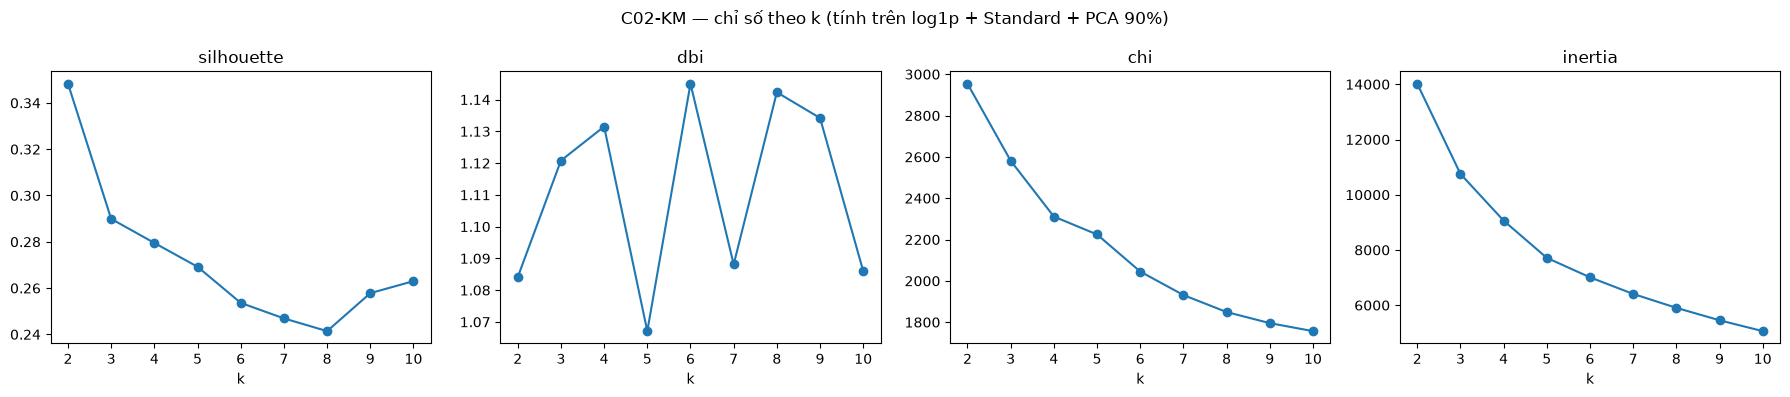

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3483,1.0841,2954.2,14020.5,2089
1,3,0.2899,1.1208,2581.3,10755.5,1253
2,4,0.2795,1.1315,2311.2,9062.3,947
3,5,0.2692,1.0671,2224.6,7714.4,661
4,6,0.2536,1.1450,2045.1,7009.4,409
5,7,0.2469,1.0881,1931.4,6408.0,369
6,8,0.2414,1.1423,1849.2,5903.7,293
7,9,0.2578,1.1342,1795.5,5454.1,149
8,10,0.2630,1.0860,1756.8,5060.9,133


In [5]:
def sweep(Zs):
    rows, labels_by_k = [], {}
    for k in K_GRID:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zs)
        labels_by_k[k] = km.labels_
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(Zs, km.labels_), 4),
                     "dbi": round(davies_bouldin_score(Zs, km.labels_), 4),
                     "chi": round(calinski_harabasz_score(Zs, km.labels_), 1),
                     "inertia": round(km.inertia_, 1),
                     "min_cluster": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(rows), labels_by_k

metrics, labels_by_k = sweep(Z)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi", "inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("C02-KM — chỉ số theo k (tính trên log1p + Standard + PCA 90%)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở **k = 2** (0,3483), rồi giảm xuống 0,2899 ở k = 3 và dao động quanh 0,24–0,28 ở k lớn hơn (thấp nhất 0,2414 ở k = 8, nhích lên 0,2578–0,2630 ở k = 9–10). DBI dao động trong khoảng 1,07–1,15 không có điểm gãy rõ; CHI giảm dần từ 2.954 (k = 2) xuống 1.757 (k = 10). Cụm nhỏ nhất vẫn có ít nhất 133 khách ở mọi k = 2–10, không còn hiện tượng vỡ ra cụm vài khách như A02-KM.

## Chọn k và huấn luyện mô hình cuối

In [6]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=n_pc, svd_solver="full")),
                  ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X)
labels = model["kmeans"].labels_
assert np.allclose(model[:-1].transform(X), Z)                   # pipeline cho đúng không gian đã quét
assert (labels == labels_by_k[best_k]).all()                     # và đúng nhãn đã quét ở trên
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    2238
1    2089
Name: Số khách, dtype: int64


**Nhận xét:** k = 2 chia 2.238 khách vào cụm 0 (51,7%) và 2.089 khách vào cụm 1 (48,3%) — hai nhóm cỡ gần bằng nhau, khác hẳn A02-KM (4.303 / 24).

## Hồ sơ cụm

Mô tả bằng trung vị **trên thang gốc** (không phải log). `Monetary_share_pct` là tỷ trọng tổng Monetary của cụm.

In [7]:
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
        QtyPerOrder=("QtyPerOrder", "median"), Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,2238,107.0,1.0,307.4,193.3,18.0,106.8,51.7,9.3
1,2089,24.0,4.0,1685.5,383.9,76.0,240.8,48.3,90.7


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị):
- Cụm 1 (2.089 khách, 48,3%): Recency 24, Frequency 4, Monetary ≈ 1.686, AOV ≈ 384, Diversity 76, QtyPerOrder ≈ 241 → **nhóm hoạt động: mua gần đây, thường xuyên, chi nhiều, đơn lớn**; chiếm 90,7% tổng Monetary.
- Cụm 0 (2.238 khách, 51,7%): Recency 107, Frequency 1, Monetary ≈ 307, AOV ≈ 193, Diversity 18, QtyPerOrder ≈ 107 → **nhóm mua ít (thường một lần), đã lâu, chi thấp, đơn nhỏ**; chỉ 9,3% Monetary.

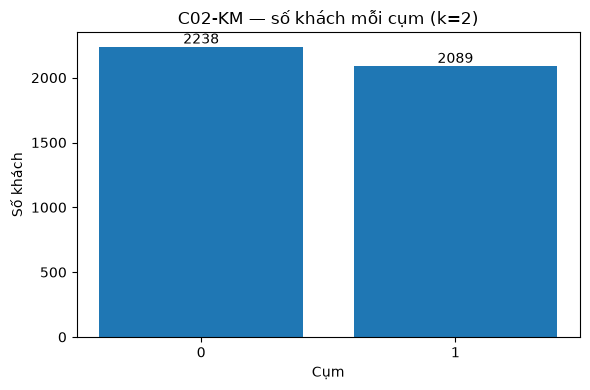

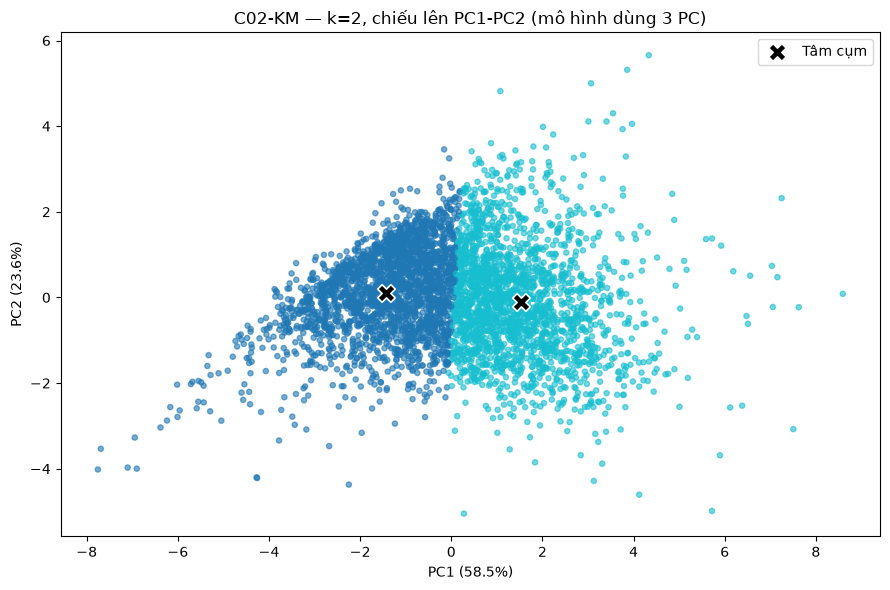

In [8]:
# Hình 1: số khách mỗi cụm
sizes = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title(f"C02-KM — số khách mỗi cụm (k={best_k})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_cluster_distribution.png", dpi=150); plt.show()

# Hình 2: chiếu lên PC1-PC2 (mô hình dùng 3 PC)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ctr = model["kmeans"].cluster_centers_
ax.scatter(ctr[:, 0], ctr[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"C02-KM — k={best_k}, chiếu lên PC1-PC2 (mô hình dùng {n_pc} PC)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hai cụm là hai nửa của cùng một đám mây liên tục, ngăn cách chủ yếu theo PC1; không có khoảng trống giữa chúng, nên đây là một đường cắt qua dải liên tục (hoạt động nhiều đến hoạt động ít) chứ không phải hai nhóm tách bạch.

## Đối chiếu C01 (dựng lại cùng điều kiện)

Dựng lại C01-KM (5 feature: `log1p` → StandardScaler → PCA 90% → K-Means, cùng lưới k, seed và quy tắc chọn) để so với C02. ARI đo mức trùng nhóm giữa hai cách chia, 1,0 là giống hệt. Vì hai thí nghiệm nằm trên hai không gian khác nhau (5 biến và 6 biến), bảng còn tính Silhouette của mỗi cách chia trên **cả hai không gian**.

In [9]:
Xc1 = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X[FEATURES_C01])
cum_c1 = np.cumsum(PCA(svd_solver="full").fit(Xc1).explained_variance_ratio_)
n_pc_c1 = int(np.searchsorted(cum_c1, PCA_VAR) + 1)
Z_c01 = PCA(n_components=n_pc_c1, svd_solver="full").fit_transform(Xc1)
metrics_c01, labels_by_k_c01 = sweep(Z_c01)
best_k_c01 = int(metrics_c01.loc[metrics_c01["silhouette"].idxmax(), "k"])
labels_c01 = labels_by_k_c01[best_k_c01]
print(f"C01 dựng lại: {n_pc_c1}/5 PC (phương sai {cum_c1[n_pc_c1-1]:.2%}) | k được chọn = {best_k_c01}")

ari_k = pd.DataFrame({"k": list(K_GRID),
                      "ARI_C02_vs_C01": [round(adjusted_rand_score(labels_by_k[k], labels_by_k_c01[k]), 4) for k in K_GRID],
                      "silhouette_C02": metrics["silhouette"].values,
                      "silhouette_C01": metrics_c01["silhouette"].values})
print("ARI giữa cách chia ở k riêng của mỗi bên:", round(adjusted_rand_score(labels, labels_c01), 4))
ari_k

C01 dựng lại: 3/5 PC (phương sai 92.40%) | k được chọn = 2
ARI giữa cách chia ở k riêng của mỗi bên: 0.7134


,k,ARI_C02_vs_C01,silhouette_C02,silhouette_C01
0,2,0.7134,0.3483,0.3754
1,3,0.5868,0.2899,0.2813
2,4,0.7313,0.2795,0.2739
3,5,0.6735,0.2692,0.2688
4,6,0.7026,0.2536,0.2566
5,7,0.4162,0.2469,0.2502
6,8,0.3659,0.2414,0.2518
7,9,0.4829,0.2578,0.2469
8,10,0.5695,0.2630,0.2474


In [10]:
def row(name, cfg, n_feat, n_components, m_row, lab):
    return {"Thí nghiệm": name, "Cấu hình": cfg, "Số biến": n_feat, "Số PC": n_components, "k": int(m_row["k"]),
            "Silhouette": m_row["silhouette"], "DBI": m_row["dbi"], "CHI": m_row["chi"], "Inertia": m_row["inertia"],
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian C01": round(silhouette_score(Z_c01, lab), 4),
            "Silhouette trên không gian C02": round(silhouette_score(Z, lab), 4)}

cmp = pd.DataFrame([
    row("C02-KM", "6 feature + log1p + Standard + PCA 90%", len(FEATURES), n_pc, metrics.loc[metrics.k == best_k].iloc[0], labels),
    row("C01-KM (dựng lại)", "5 feature + log1p + Standard + PCA 90%", len(FEATURES_C01), n_pc_c1,
        metrics_c01.loc[metrics_c01.k == best_k_c01].iloc[0], labels_c01),
])
cmp

,Thí nghiệm,Cấu hình,Số biến,Số PC,k,Silhouette,DBI,CHI,Inertia,Kích thước cụm,Silhouette trên không gian C01,Silhouette trên không gian C02
0,C02-KM,6 feature + log1p + Standard + PCA 90%,6,3,2,0.3483,1.0841,2954.2,14020.5,"[2238, 2089]",0.3558,0.3483
1,C01-KM (dựng lại),5 feature + log1p + Standard + PCA 90%,5,3,2,0.3754,1.0147,3375.4,11227.5,"[2452, 1875]",0.3754,0.3474


In [11]:
# Khách nào đổi nhóm khi thêm QtyPerOrder? (nhóm hoạt động = cụm có Monetary median cao hơn)
act02 = labels == profile(labels)["Monetary"].idxmax()
act01 = labels_c01 == profile(labels_c01)["Monetary"].idxmax()
groups = {"Hoạt động ở cả C01 và C02": act01 & act02, "Mua ít ở cả C01 và C02": ~act01 & ~act02,
          "C01 mua ít -> C02 hoạt động": ~act01 & act02, "C01 hoạt động -> C02 mua ít": act01 & ~act02}
movers = pd.DataFrame([{"Nhóm": n_, "Số khách": int(m.sum()), **X[m].median().round(1).to_dict()} for n_, m in groups.items()])
n_move = int((act01 ^ act02).sum())
print(f"Số khách đổi nhóm: {n_move} ({n_move / len(X):.1%})")
print("\nBảng chéo (hàng: cụm C01, cột: cụm C02):")
print(pd.crosstab(pd.Series(labels_c01, name="C01"), pd.Series(labels, name="C02")).to_string())
movers

Số khách đổi nhóm: 336 (7.8%)

Bảng chéo (hàng: cụm C01, cột: cụm C02):
C02     0     1
C01            
0      61  1814
1    2177   275


,Nhóm,Số khách,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder
0,Hoạt động ở cả C01 và C02,1814,20.0,5.0,1904.5,369.5,87.0,226.4
1,Mua ít ở cả C01 và C02,2177,111.0,1.0,302.6,195.4,17.0,109.3
2,C01 mua ít -> C02 hoạt động,275,78.0,2.0,806.1,494.2,40.0,326.5
3,C01 hoạt động -> C02 mua ít,61,25.0,4.0,672.8,163.7,45.0,68.0


**Nhận xét:**
- **Cả hai chọn k = 2** theo Silhouette (C01 0,3754; C02 0,3483; hai giá trị nằm trên hai không gian khác nhau nên không so trực tiếp): một nhóm hoạt động chiếm đa số Monetary và một nhóm mua ít. Ở cả hai, k = 3 chỉ còn Silhouette 0,28–0,29.
- **Khác nhau ở biên, không phải ở cấu trúc:** ARI ở k = 2 là 0,7134; qua các k từ 2 đến 10, ARI dao động 0,37–0,73. **336 khách (7,8%) đổi nhóm.**
- **QtyPerOrder kéo ranh giới theo cỡ đơn hàng:** 275 khách mua ít ở C01 sang nhóm hoạt động ở C02 có QtyPerOrder median 326,5 và AOV 494 (so với 109 ở nhóm mua ít ổn định và 226 ở nhóm hoạt động ổn định); ngược lại 61 khách rời nhóm hoạt động có QtyPerOrder chỉ 68 và AOV 164 dù Frequency 4.
- **Chất lượng cụm gần như không đổi:** trên không gian C02, cách chia của C01 và C02 có Silhouette gần bằng nhau (0,3474 so với 0,3483); trên không gian C01, cách chia C01 cao hơn một chút (0,3754 so với 0,3558). Thêm QtyPerOrder không làm cụm tốt hơn.

## Lưu kết quả

In [12]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_c02_labels.csv", index=False)
joblib.dump(model, "kmeans_model.pkl")

m = metrics.loc[metrics.k == best_k].iloc[0]
params = {"experiment": "C02-KM", "features": FEATURES,
          "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes", "QtyPerOrder": "avg_quantity_per_order"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "n_customers": int(len(X)),
          "silhouette": float(m["silhouette"]), "dbi": float(m["dbi"]), "chi": float(m["chi"]), "inertia": float(m["inertia"]),
          "r2_logQtyPerOrder_on_C01_features": round(float(r2_qty), 4),
          "kmeans_params": model["kmeans"].get_params()}
json.dump(params, open("kmeans_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_model.pkl', 'kmeans_params.json'] ['kmeans_c02_labels.csv']


## Working_details

Ghi bảng tóm tắt theo đúng bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng theo k, bảng cụm), thêm bảng đối chiếu C01.

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "KMeans_C02"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

put("A1", "THÍ NGHIỆM K-MEANS — C02 (RFM + AOV + Diversity + QtyPerOrder, log1p, Standard, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; chỉ số tính trên Z (không gian đã fit). Khác C01 ở việc thêm QtyPerOrder")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity, QtyPerOrder"),
        ("Dữ liệu train", f"Z (log1p → Standard → PCA, {n_pc} PC)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", "k-means++"), ("n_init", N_INIT)]
right = [("max_iter", 300), ("tol", 0.0001), ("Tổng khách hàng", int(len(X))), ("Số cụm", best_k),
         ("PCA", f"90% → {n_pc}/{len(FEATURES)} PC (phương sai {cum[n_pc-1]:.2%})"),
         ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)
ws["E6"].number_format = "0.0000"

for c, v in zip("ABCDEF", ["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]): put(f"{c}12", v, bold=True)
for i, r in enumerate(metrics.itertuples(), start=13):
    put(f"A{i}", int(r.k)); put(f"B{i}", r.silhouette, fmt="0.0000"); put(f"C{i}", r.dbi, fmt="0.0000")
    put(f"D{i}", r.chi, fmt="0.00"); put(f"E{i}", r.inertia, fmt="0.00")
    note = "k được chọn (Silhouette lớn nhất)" if r.k == best_k else ""
    if r.min_cluster <= 5: note = (note + "; " if note else "") + f"cụm nhỏ nhất chỉ {r.min_cluster} khách"
    put(f"F{i}", note)

r0 = 13 + len(metrics) + 2
hdr = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
       "Monetary (median)", "AOV (median)", "Diversity (median)", "QtyPerOrder (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJK", hdr): put(f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(f"A{j}", int(cl)); put(f"B{j}", mo_ta(p)); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["AOV"]), fmt="0.00"); put(f"I{j}", float(p["Diversity"])); put(f"J{j}", float(p["QtyPerOrder"]), fmt="0.00")
    put(f"K{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu C01-KM (dựng lại; chỉ số tính trên không gian đã fit của từng thí nghiệm)", bold=True)
for c, v in zip("ABCDEFGHIJ", ["Thí nghiệm", "Cấu hình", "k", "Silhouette", "DBI", "CHI", "Inertia", "Kích thước cụm",
                                "Silhouette trên không gian C01", "Silhouette trên không gian C02"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], int(r[4]), float(r[5]), float(r[6]), float(r[7]), float(r[8]), str(r[9]), float(r[10]), float(r[11])]
    for c, v in zip("ABCDEFGHIJ", vals):
        put(f"{c}{j}", v, fmt="0.0000" if c in "DEIJ" else ("0.00" if c in "FG" else None))
k2 = float(ari_k.loc[ari_k.k == 2, "ARI_C02_vs_C01"].iloc[0])
put(f"A{r1+5}", f"ARI C02 vs C01 ở k riêng (k = 2): {adjusted_rand_score(labels, labels_c01):.4f} | qua k = 2..10: {ari_k['ARI_C02_vs_C01'].min():.2f}–{ari_k['ARI_C02_vs_C01'].max():.2f}")
put(f"A{r1+6}", f"Khách đổi nhóm khi thêm QtyPerOrder: {n_move} ({n_move / len(X):.1%})")
put(f"A{r1+7}", f"R² của log1p(QtyPerOrder) theo 5 feature của C01: {r2_qty:.4f}")
put(f"A{r1+8}", "Silhouette/DBI/CHI của hai thí nghiệm tính trên hai không gian khác nhau nên không so trực tiếp; hai cột cuối là phép so cùng không gian.")

for col, w in zip("ABCDEFGHIJK", [16, 22, 17, 19, 20, 21, 25, 22, 22, 24, 22]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_KMeans_C02.xlsx")
print("Đã lưu Working_details_KMeans_C02.xlsx")

Đã lưu Working_details_KMeans_C02.xlsx


## Kết luận C02-KM

- **K-Means vẫn chọn k = 2** (Silhouette 0,3483; k = 3 chỉ 0,2899): nhóm hoạt động (2.089 khách, 48,3%) giữ 90,7% Monetary và nhóm mua ít (2.238 khách, 51,7%) giữ 9,3%. Cụm cân đối, không còn cụm vài khách như A02-KM.
- **Thêm QtyPerOrder chỉ dịch ranh giới, không đổi cấu trúc:** so với C01-KM dựng lại, ARI ở k = 2 là 0,7134 và 336 khách (7,8%) đổi nhóm, chủ yếu theo cỡ đơn hàng (khách đơn lớn, QtyPerOrder ≈ 327, được xếp vào nhóm hoạt động). Chất lượng cụm trên cùng không gian gần như bằng nhau.
- **QtyPerOrder không thừa hoàn toàn:** R² = 0,7199 theo 5 feature của C01 (còn ≈ 28% thông tin độc lập), ít thừa hơn AOV (R² = 0,9832 ở C01), nhưng tác động lên cụm vẫn nhỏ. PCA giữ 3/6 PC nhưng chỉ vừa qua ngưỡng 90% (90,89%).
- **Giới hạn:** chọn k theo Silhouette cho đúng 2 cụm, tức K-Means chỉ cắt dải khách thành "hoạt động" và "mua ít"; Silhouette không so trực tiếp được giữa các không gian khác nhau.
- **Bước kế tiếp:** C04-DB (thêm QtyPerOrder và Tenure, DBSCAN) so với C01 và C02.